# Exploratory_Data_Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# import dataset
date_cols = ['order_purchase_timestamp', 'order_approved_at',
             'order_delivered_carrier_date', 'order_delivered_customer_date',
             'order_estimated_delivery_date']

order_items_date_columns = ['shipping_limit_date']

review_date_columns = ['review_creation_date','review_answer_timestamp']

orders_cleaned      = pd.read_csv('../data/interim/olist_orders_cleaned.csv', parse_dates=date_cols)
order_items_cleaned = pd.read_csv('../data/interim/olist_order_items_cleaned.csv', parse_dates=order_items_date_columns)
customers_cleaned   = pd.read_csv('../data/interim/olist_customers_cleaned.csv')
payments_cleaned    = pd.read_csv('../data/interim/olist_ payments_cleaned.csv')
products_cleaned    = pd.read_csv('../data/interim/olist_products_cleaned.csv')
translation_cleaned = pd.read_csv('../data/interim/olist_ translation_cleaned.csv')
geolocation_cleaned = pd.read_csv('../data/interim/olist_geolocation_cleaned.csv')
reviews_cleaned     = pd.read_csv('../data/interim/olist_ reviews_cleaned.csv', parse_dates= review_date_columns)
sellers_cleaned     = pd.read_csv('../data/interim/olist_sellers_cleaned.csv')

# EDA-01 — Univariate Analysis

## Orders Analysis

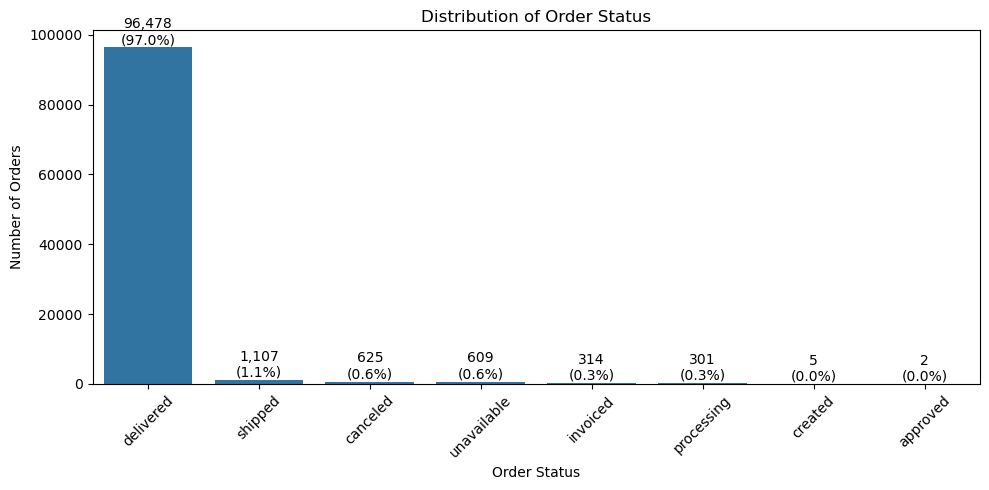

In [3]:
order_status_counts = orders_cleaned["order_status"].value_counts()
total_orders = order_status_counts.sum()

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=order_status_counts.index,
    y=order_status_counts.values
    
)

plt.title("Distribution of Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

# Add count and percentage labels
for bar in ax.patches:
    count = bar.get_height()
    percentage = (count / total_orders) * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count,
        f"{int(count):,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

#### Key Insights

- The 97% of orders have a `delivered` status, indicating that most orders in the dataset were successfully completed.
- `shipped` and `canceled` orders represent a much smaller share of the total order volume.

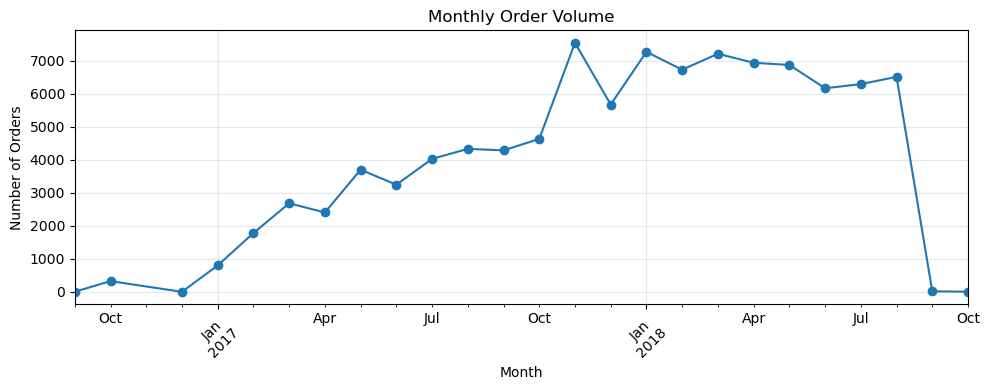

In [4]:
monthly_orders = (
    orders_cleaned.groupby(orders_cleaned['order_purchase_timestamp'].dt.to_period("M")).size()
    )
monthly_orders

plt.figure(figsize=(10, 4))

monthly_orders.plot(kind="line", marker="o")

plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Key Insights

- Monthly order volume shows a clear growth trend during the earlier part of the observed period.
- Order volume reached its highest level toward the later part of the main growth period.
- A noticeable decline appears near the end of the observation period . the decline may be influenced by incomplete observations in the final period.

In [5]:
valid_orders = orders_cleaned[orders_cleaned['purchase_to_customer_hours'] >= 0]
to_days = (valid_orders['purchase_to_customer_hours'] / 24)

to_days.agg(['min', 'mean', 'median','max'])

min         0.533414
mean       12.558702
median     10.217755
max       209.628611
Name: purchase_to_customer_hours, dtype: float64

In [6]:
to_days.describe(percentiles=[.25, .5, .75, .9, .95])

count    96476.000000
mean        12.558702
std          9.546530
min          0.533414
25%          6.766403
50%         10.217755
75%         15.720327
90%         23.097604
95%         29.276016
max        209.628611
Name: purchase_to_customer_hours, dtype: float64

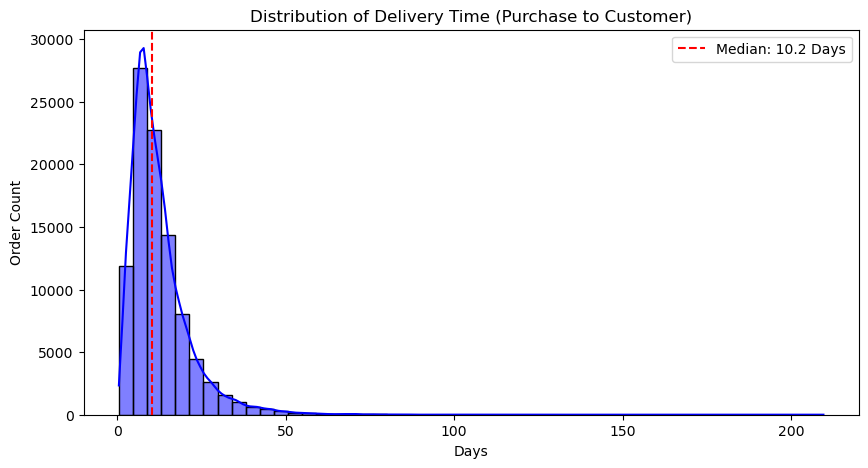

In [7]:
plt.figure(figsize=(10, 5))
sns.histplot(to_days, kde=True, bins=50, color='blue')
plt.title('Distribution of Delivery Time (Purchase to Customer)')
plt.xlabel('Days')
plt.ylabel('Order Count')
plt.axvline(to_days.median(), color='red', linestyle='--', label=f'Median: {to_days.median():.1f} Days')
plt.legend()
plt.show()

 #### Key Observation
Delivery time distribution is right-skewed, with most orders concentrated at shorter delivery times and a smaller number of orders taking considerably longer.

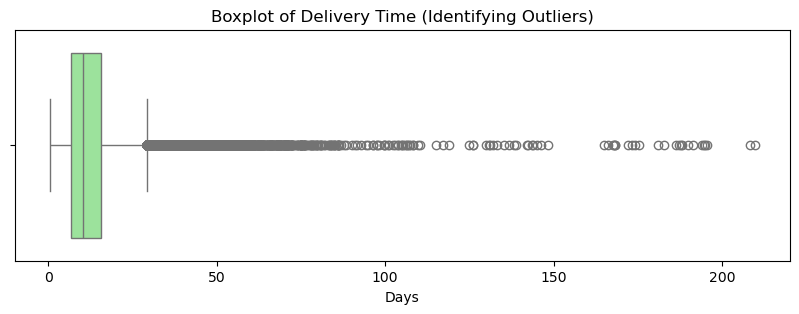

In [8]:
plt.figure(figsize=(10, 3))
sns.boxplot(x=to_days, color='lightgreen')
plt.title('Boxplot of Delivery Time (Identifying Outliers)')
plt.xlabel('Days')
plt.show()

#### Key Observation

- The boxplot confirms the presence of a right-skewed distribution and several high-duration outliers.
- These outliers represent unusually long delivery times and were retained because they may reflect real business cases.

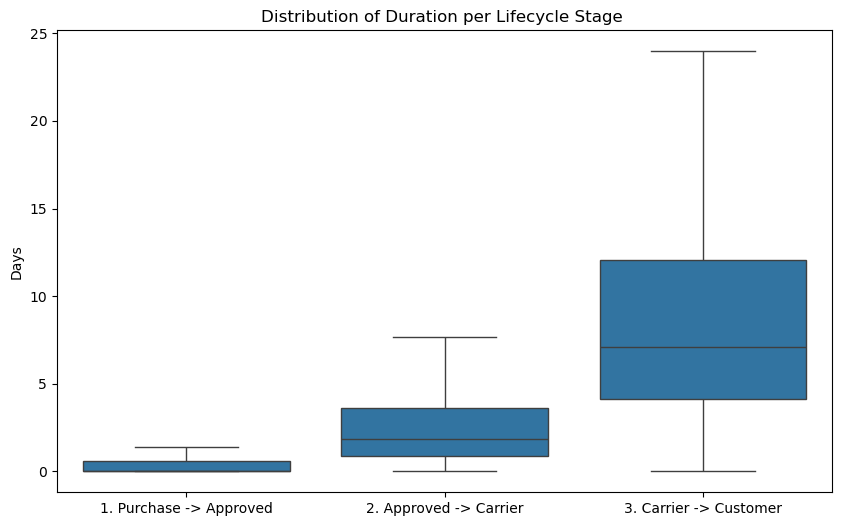

In [9]:
valid_lifecycle = orders_cleaned[
    (orders_cleaned['purchase_to_approved_hours'] >= 0) &
    (orders_cleaned['approval_to_carrier_hours'] >= 0) &
    (orders_cleaned['carrier_to_customer_hours'] >= 0)
]

lifecycle_long = pd.DataFrame({
    '1. Purchase -> Approved': valid_lifecycle['purchase_to_approved_hours'] / 24,
    '2. Approved -> Carrier': valid_lifecycle['approval_to_carrier_hours'] / 24,
    '3. Carrier -> Customer': valid_lifecycle['carrier_to_customer_hours'] / 24
}).melt(var_name='Stage', value_name='Days')

plt.figure(figsize=(10, 6))
sns.boxplot(data=lifecycle_long, x='Stage', y='Days', showfliers=False)
plt.title('Distribution of Duration per Lifecycle Stage ')
plt.ylabel('Days')
plt.xlabel('')
plt.show()

#### Key Observation
Carrier → Customer has the highest median duration and therefore represents the longest stage of the observed order lifecycle.

In [10]:
## 4. Delivery Performance

delivered_valid = orders_cleaned[
    (orders_cleaned['order_delivered_customer_date'].notna())
].copy()

delivered_valid['is_on_time'] = (
    delivered_valid['order_delivered_customer_date'] <= delivered_valid['order_estimated_delivery_date']
)

In [11]:
on_time_rate = delivered_valid['is_on_time'].mean() * 100
print(f"on time rate :  {on_time_rate:.2f}%")
print(f"total orders : {len(delivered_valid)}")

on time rate :  91.89%
total orders : 96476


#### Key Insights

- Approximately 91.89% of delivered orders were delivered on or before the estimated delivery date.
- This indicates that the majority of orders were delivered within the promised timeframe.
- However, approximately 8.11% of delivered orders were delivered after the estimated date, indicating that late delivery remains a relevant operational issue.
- The overall on-time delivery rate provides a high-level view of delivery performance, but it does not explain the causes of late deliveries.

## Order Items Analysis

### How are item prices distributed?

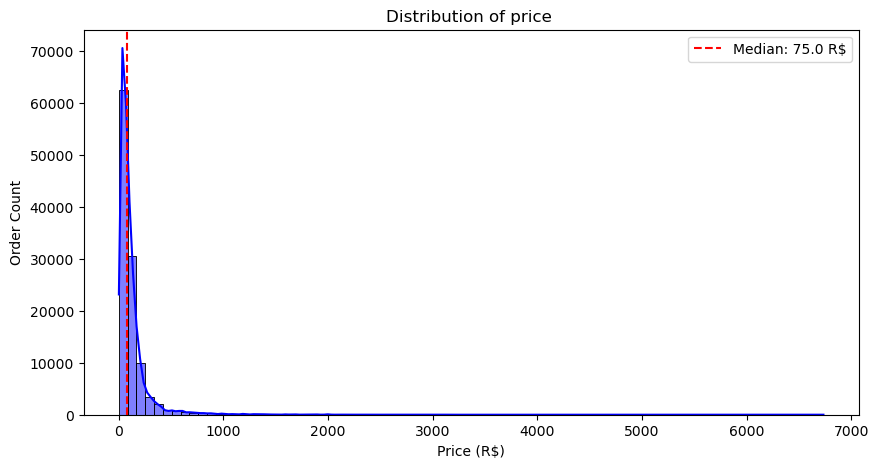

count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
90%         229.800000
95%         349.900000
max        6735.000000
Name: price, dtype: float64

In [12]:
peice_dis = order_items_cleaned['price']
plt.figure(figsize=(10, 5))
sns.histplot(peice_dis, kde=True, bins=80, color='blue')
plt.title('Distribution of price ')
plt.xlabel('Price (R$)')
plt.ylabel('Order Count')
plt.axvline(peice_dis.median(), color='red', linestyle='--', label=f'Median: {peice_dis.median():.1f} R$')
plt.legend()
plt.show()

order_items_cleaned['price'].describe(
    percentiles=[.25, .5, .75, .9, .95]
)

#### Key Observation

- The mean item price is substantially higher than the median, and the distribution is positively skewed.
- Most items are concentrated at relatively lower price levels, while a smaller number of high-priced items create a long right tail.

### How are freight costs distributed?

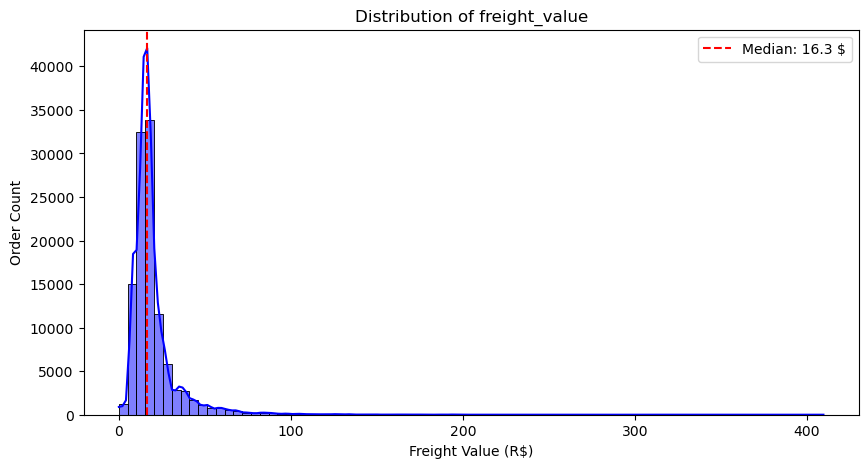

count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
90%          34.041000
95%          45.120000
max         409.680000
Name: freight_value, dtype: float64

In [13]:
freight_value_dis = order_items_cleaned['freight_value']
plt.figure(figsize=(10, 5))
sns.histplot(freight_value_dis, kde=True, bins=80, color='blue')
plt.title('Distribution of freight_value')
plt.xlabel('Freight Value (R$)')
plt.ylabel('Order Count')
plt.axvline(freight_value_dis.median(), color='red', linestyle='--', label=f'Median: {freight_value_dis.median():.1f} $')
plt.legend()
plt.show()

order_items_cleaned['freight_value'].describe(
    percentiles=[.25, .5, .75, .9, .95]
)

In [14]:
zero_freight = (order_items_cleaned['freight_value'] == 0).sum()

zero_freight_pct = (
    zero_freight / len(order_items_cleaned) * 100
)

print(f"Zero freight items: {zero_freight:,}")
print(f"Percentage: {zero_freight_pct:.2f}%")

Zero freight items: 383
Percentage: 0.34%


#### key observation 

- 383 of the order items have 0 shipping costs, which is likely due to proximity or discounts.

### How many items do customers typically purchase per order?

In [15]:
items_per_order = (
    order_items_cleaned
    .groupby('order_id')['order_item_id']
    .max()
)

items_per_order.describe(percentiles=[.25, .5, .75, .9, .95])

count    98666.000000
mean         1.141731
std          0.538452
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
90%          1.000000
95%          2.000000
max         21.000000
Name: order_item_id, dtype: float64

#### Key Observations

- Most orders contain a single item, as the median number of items per order is 1.
- At least 90% of orders contain only one item.

### Is item price associated with freight value?

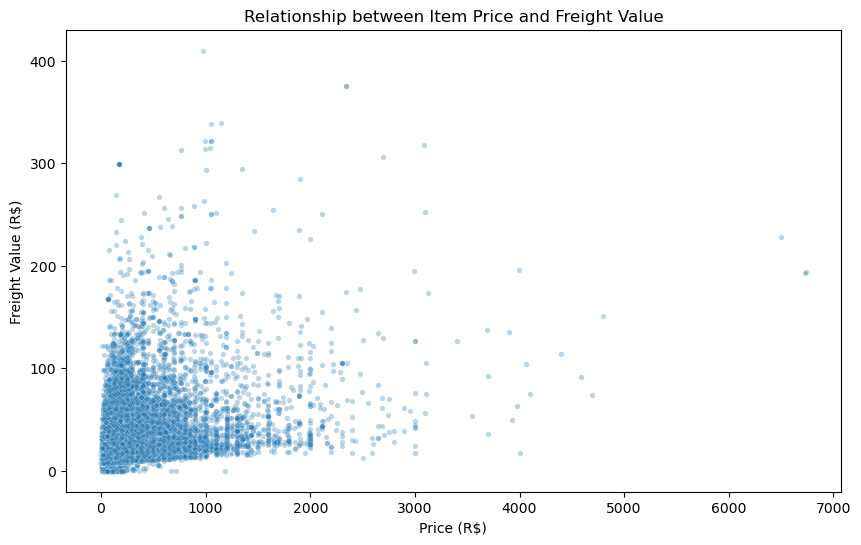

np.float64(0.434190324041091)

In [16]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=order_items_cleaned, x='price', y='freight_value', alpha=0.3, s=15)
plt.title('Relationship between Item Price and Freight Value')
plt.xlabel('Price (R$)')
plt.ylabel('Freight Value (R$)')
plt.show()

correlation_spearman = order_items_cleaned['price'].corr(order_items_cleaned['freight_value'], method='spearman')
correlation_spearman

#### Key Observations

- A moderate positive monotonic relationship exists between item price and freight value (Spearman ρ = 0.434).
- Higher-priced items tend to be associated with higher freight values, but the relationship is not strong enough to explain freight costs by price alone.
- The wide dispersion of freight values at similar price levels suggests that other factors may also be associated with shipping costs.

### How significant is freight cost relative to item price?

In [17]:
order_items_cleaned['freight_ratio'] = (
    order_items_cleaned['freight_value']
    / order_items_cleaned['price']
)
order_items_cleaned['freight_ratio'].describe(
    percentiles=[.5, .75, .9, .95]
)

count    112650.000000
mean          0.320864
std           0.349894
min           0.000000
50%           0.231356
75%           0.393036
90%           0.642857
95%           0.874702
max          26.235294
Name: freight_ratio, dtype: float64

## Customers Analysis

### What percentage of customers have placed more than one order?

In [18]:
orders_per_customer = (
    customers_cleaned
    .groupby('customer_unique_id')
    .size()
)

orders_per_customer.describe(
    percentiles=[.5, .75, .9, .95, .99]
)


count    96096.000000
mean         1.034809
std          0.214384
min          1.000000
50%          1.000000
75%          1.000000
90%          1.000000
95%          1.000000
99%          2.000000
max         17.000000
dtype: float64

In [19]:
repeat_customers = (orders_per_customer > 1).sum()
one_time_customers = (orders_per_customer == 1).sum()

total_customers = len(orders_per_customer)

print(f"One-time customers: {one_time_customers:,}")
print(f"Repeat customers: {repeat_customers:,}")
print(f"Repeat customer rate: {repeat_customers / total_customers * 100:.2f}%")

One-time customers: 93,099
Repeat customers: 2,997
Repeat customer rate: 3.12%


#### Key Observations

- The vast majority of customers placed only one order.
- Only 3.12% of unique customers placed more than one order.
- The median number of orders per customer is 1, indicating that one-time purchasing is the dominant customer behavior.
- A small number of customers placed substantially more orders, with the maximum reaching 17 orders.

#### Business Interpretation

- The customer base is predominantly composed of one-time customers, while repeat customers represent a relatively small segment.
- This suggests that customer retention and repeat purchasing may be important areas for further business investigation.

### Where are customers located?

In [20]:
customers_cleaned['customer_city'].value_counts().head(10)

customer_city
sao paulo                15540
rio de janeiro            6882
belo horizonte            2773
brasilia                  2131
curitiba                  1521
campinas                  1444
porto alegre              1379
salvador                  1245
guarulhos                 1189
sao bernardo do campo      938
Name: count, dtype: int64

#### Key Observations

- São Paulo is the most common customer city, with 15,540 customer records.
- Rio de Janeiro is the second most represented city, with 6,882 customer records.
- The customer base is concentrated in a relatively small number of major cities, with São Paulo accounting for a substantially larger share than the other cities.

### How geographically concentrated is the customer base?

In [21]:
state_share = (
    customers_cleaned['customer_state']
    .value_counts(normalize=True)
    .head(5)
    .sum()
)

print(f"Top 5 states share: {state_share * 100:.2f}%")

Top 5 states share: 77.18%


#### Key Observation

- The top five customer states account for 77.18% of all customer records, indicating a high geographic concentration of the customer base.

#### Business Interpretation

- Customer demand is heavily concentrated in a small number of states, which may be relevant for logistics planning, regional operations, and market prioritization.

## Product Analysis

In [22]:
prod_cats = products_cleaned['product_category_name'].dropna().unique()
trans_cats = translation_cleaned['product_category_name'].unique()
still_missing = set(prod_cats) - set(trans_cats)
print("categorys without name :", still_missing)

categorys without name : {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}


In [23]:
unique_category_products = products_cleaned['product_category_name'].nunique()
unique_category_translation = translation_cleaned['product_category_name'].nunique()

print("number of unique categories in products:", unique_category_products)
print("number of unique categories in translation:", unique_category_translation)

number of unique categories in products: 73
number of unique categories in translation: 71


#### 2 Category translations added manually (not present in the original dataset)

In [24]:
missing_rows = pd.DataFrame({
    'product_category_name': [
        'portateis_cozinha_e_preparadores_de_alimentos',
        'pc_gamer'
    ],
    'product_category_name_english': [
        'kitchen_portables_and_food_preparators',
        'pc_gamer'
    ]
})
translation_cleaned = pd.concat([translation_cleaned, missing_rows], ignore_index=True)

print("number of rows after concat   :", len(translation_cleaned))  # should be 71 + 2 = 73


number of rows after concat   : 73


In [25]:
products_cleaned = products_cleaned.merge(
    translation_cleaned[['product_category_name', 'product_category_name_english']],
    on='product_category_name',
    how='left'
)

In [26]:
print("number of rows before merge:", len(products_cleaned))  # should be 32951

number of rows before merge: 32951


In [27]:
products_cleaned['product_category_name_english'].isna().sum()

np.int64(610)

#### Key Observation

- Two product categories were initially missing from the translation table.
- These categories were manually mapped to their English names before joining the translation table.
- After the merge, some products still have missing English category names.
- These remaining missing values are associated with products without an assigned original product category.

### How diverse are product physical dimensions?


In [28]:
physical_cols = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
products_valid = products_cleaned[products_cleaned['product_weight_g'] > 0]  # flag zero weight 
products_valid[physical_cols].describe()

,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32945.000000,32945.000000,32945.000000,32945.000000
mean,2276.748885,30.815177,16.936682,23.195902
std,4282.225204,16.915482,13.638093,12.079548
min,2.000000,7.000000,2.000000,6.000000
25%,300.000000,18.000000,8.000000,15.000000
50%,700.000000,25.000000,13.000000,20.000000
75%,1900.000000,38.000000,21.000000,30.000000
max,40425.000000,105.000000,105.000000,118.000000


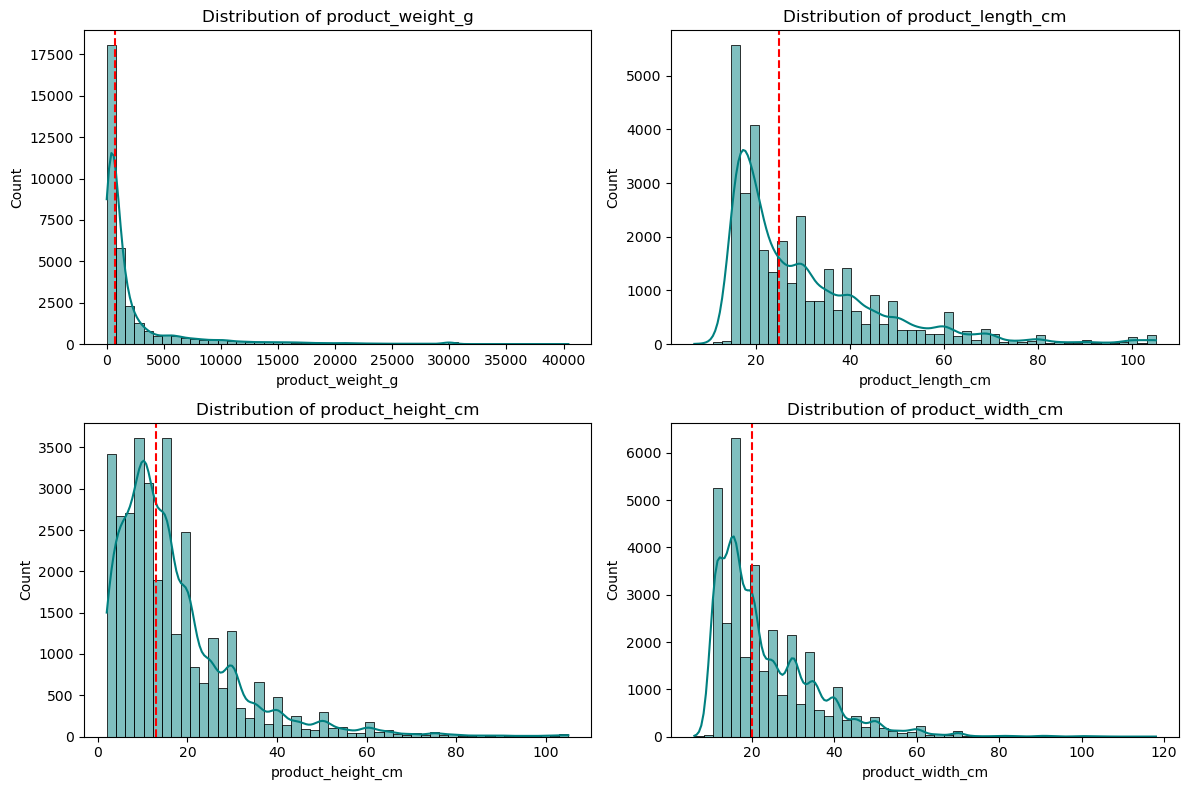

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), physical_cols):
    sns.histplot(products_valid[col], bins=50, kde=True, ax=ax, color='teal')
    ax.set_title(f'Distribution of {col}')
    ax.axvline(products_valid[col].median(), color='red', linestyle='--')
plt.tight_layout()
plt.show()


#### Key Observations

- Product physical attributes show highly uneven distributions, with most products concentrated at relatively smaller values.
- The distributions contain long right tails, indicating the presence of a smaller number of products with substantially larger physical dimensions or weight.
- These variations in physical characteristics may be relevant when investigating differences in freight costs.

### What product categories are most common?

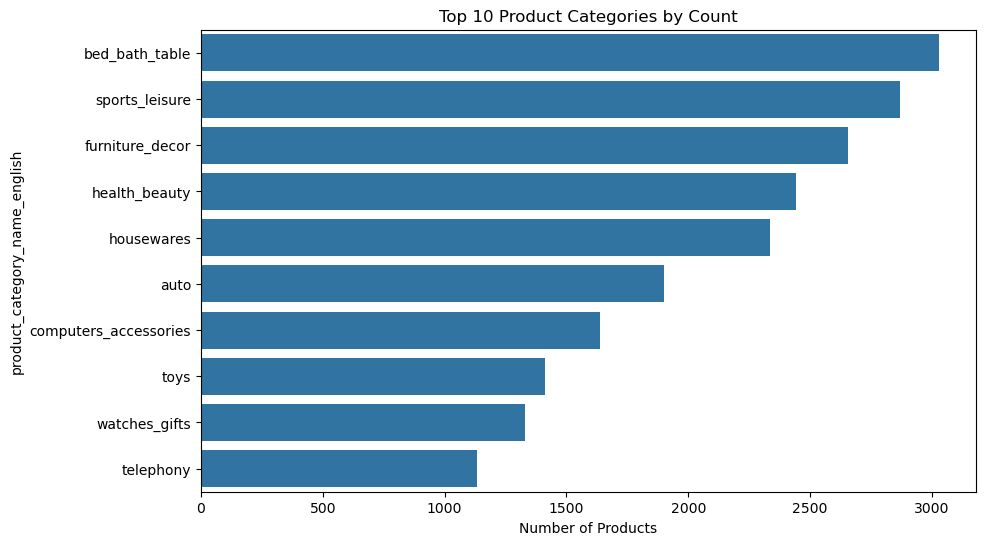

In [30]:
top_categories = products_cleaned['product_category_name_english'].value_counts().head(10)
plt.figure(figsize=(10,6))
sns.barplot(x=top_categories.values, y=top_categories.index, orient='h')
plt.title('Top 10 Product Categories by Count')
plt.xlabel('Number of Products')
plt.show()

#### Key Observation

- The product catalog contains a large number of distinct product categories.
- A relatively small number of categories account for a substantial share of the available products.
- The distribution of products across categories is uneven, with some categories containing considerably more products than others.

## Sellers Analysis 

### Where are sellers located?


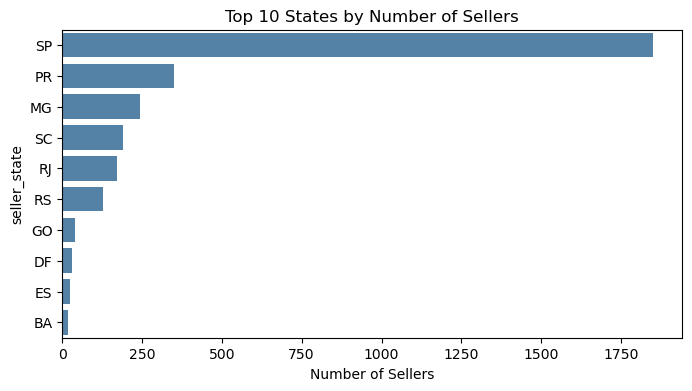

In [31]:
top_seller_states = sellers_cleaned['seller_state'].value_counts().head(10)
plt.figure(figsize=(8,4))
sns.barplot(x=top_seller_states.values, y=top_seller_states.index, orient='h', color='steelblue')
plt.title('Top 10 States by Number of Sellers')
plt.xlabel('Number of Sellers')
plt.show()

#### Key Observations

- Seller distribution is uneven across Brazilian states.
- A limited number of states contain a large proportion of the seller network.

### How geographically concentrated is the seller network?

In [32]:
seller_state_share = (
    sellers_cleaned['seller_state']
    .value_counts(normalize=True)
    .head(5)
    .sum()
)

print(f"Top 5 seller states share: {seller_state_share * 100:.2f}%")

Top 5 seller states share: 90.57%


#### Key Observation

- The top five states account for approximately 90% of all sellers.
- This indicates that the seller network is highly concentrated geographically.
 
 #### Business Insight

- A high concentration of sellers in a limited number of states may have implications for logistics network design and regional operations.
- The concentration also suggests that seller activity is not evenly distributed across the country.

## Geolocation Analysis 

In [33]:
import unicodedata

def normalize_city(city):
    city = str(city).lower().strip()
    city = ''.join(
        c for c in unicodedata.normalize('NFKD', city)
        if not unicodedata.combining(c)
    )
    return city

geolocation_cleaned['city_normalized'] = (
    geolocation_cleaned['geolocation_city'].apply(normalize_city)
)

city_variations = (
    geolocation_cleaned
    .groupby('city_normalized')['geolocation_city']
    .nunique()
    .sort_values(ascending=False)
)

cities_with_variations = (
    geolocation_cleaned[
        geolocation_cleaned['city_normalized'].isin(
            city_variations[city_variations > 1].index
        )
    ]
    [['geolocation_city', 'city_normalized']]
    .drop_duplicates()
    .sort_values('city_normalized')
)

cities_with_variations

,geolocation_city,city_normalized
792364,abadiania,abadiania
792411,abadiânia,abadiania
598309,abaete,abaete
598338,abaeté,abaete
697165,abaíra,abaira
...,...,...
719980,xexeu,xexeu
759283,ze doca,ze doca
759425,zé doca,ze doca
932551,zortea,zortea


In [34]:
before = len(geolocation_cleaned)

geolocation_cleaned = geolocation_cleaned.drop_duplicates().copy()

after = len(geolocation_cleaned)

print(f"Removed rows: {before - after:,}")
print(f"Rows after deduplication: {after:,}")

Removed rows: 261,831
Rows after deduplication: 738,332


In [35]:
geolocation_cleaned.duplicated().sum()

np.int64(0)

In [36]:
geolocation_cleaned['geolocation_city'].nunique()

8011

In [37]:
geolocation_cleaned['city_normalized'].nunique()

5968

In [38]:
zip_record_counts = (
    geolocation_cleaned
    .groupby('geolocation_zip_code_prefix')
    .size()
)

zip_record_counts.describe()

count    19015.000000
mean        38.828925
std         50.875735
min          1.000000
25%          8.000000
50%         23.000000
75%         49.000000
max        779.000000
dtype: float64

In [39]:
(zip_record_counts > 1).mean() * 100

np.float64(93.7312647909545)

#### Key Observation

- Multiple geographic records exist for the same ZIP code prefix.
- Therefore, a ZIP code prefix does not uniquely identify a single latitude-longitude coordinate in the geolocation table.
#### Business Insight

- Directly joining geolocation to customer or seller records using ZIP code prefix can create multiple matches and duplicate customer or seller records.
- Geographic joins therefore require an aggregation or coordinate-selection strategy before they are used for distance analysis.

In [40]:
geo_variability = (
    geolocation_cleaned
    .groupby('geolocation_zip_code_prefix')
    .agg(
        latitude_std=('geolocation_lat', 'std'),
        longitude_std=('geolocation_lng', 'std'),
        records=('geolocation_lat', 'size')
    )
)

geo_variability.sort_values(
    'records',
    ascending=False
).head(10)

,latitude_std,longitude_std,records
geolocation_zip_code_prefix,,,
38400,0.010280,0.011203,779
35500,0.012673,0.011990,751
11680,0.035589,0.051913,727
11740,0.024225,0.042186,678
36400,0.103187,0.160052,627
38408,0.007099,0.013257,621
39400,0.011045,0.007477,620
35162,0.009115,0.012247,611
37200,0.010163,0.009065,596


## Payment Analysis

### What percentage of orders use each payment method?
### Which payment methods account for the largest share of payment value?

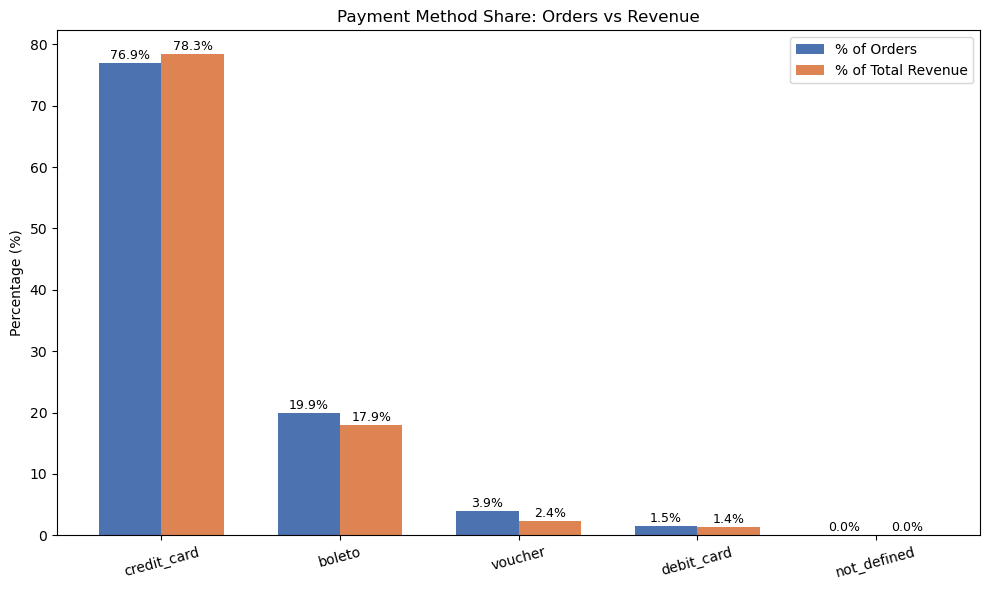

In [41]:
orders_by_payment = payments_cleaned.groupby('payment_type')['order_id'].nunique().sort_values(ascending=False)
payment_order_share = orders_by_payment / payments_cleaned['order_id'].nunique() * 100

payment_value = payments_cleaned.groupby('payment_type')['payment_value'].sum().sort_values(ascending=False)
payment_value_share = (payment_value / payment_value.sum() * 100).reindex(payment_order_share.index)

x = np.arange(len(payment_order_share))
width = 0.35
fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, payment_order_share.values, width, label='% of Orders', color='#4C72B0')
bars2 = ax.bar(x + width/2, payment_value_share.values, width, label='% of Total Revenue', color='#DD8452')

ax.set_xticks(x)
ax.set_xticklabels(payment_order_share.index, rotation=15)
ax.set_ylabel('Percentage (%)')
ax.set_title('Payment Method Share: Orders vs Revenue')
ax.legend()

for bars in [bars1, bars2]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{h:.1f}%', xy=(bar.get_x()+bar.get_width()/2, h),
                    xytext=(0,3), textcoords='offset points', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

#### Key Observation 

- Credit card is also the most dominant payment method (76.9% of orders) and a percentage of revenues (78.3%).
- Vouchers are the only method with a significant gap between the two: they account for 3.9% of orders but only 2.4% of revenues — meaning their share of the number of orders is approximately 1.6 times the value of the Real.
- This means that the amount of orders paid with coupons (~66 Real) is significantly lower than other methods (credit card ~163 Real) 
- Customers who buy with vouchers make smaller purchases.

## Reviews Analysis

### How satisfied are customers based on their review scores?

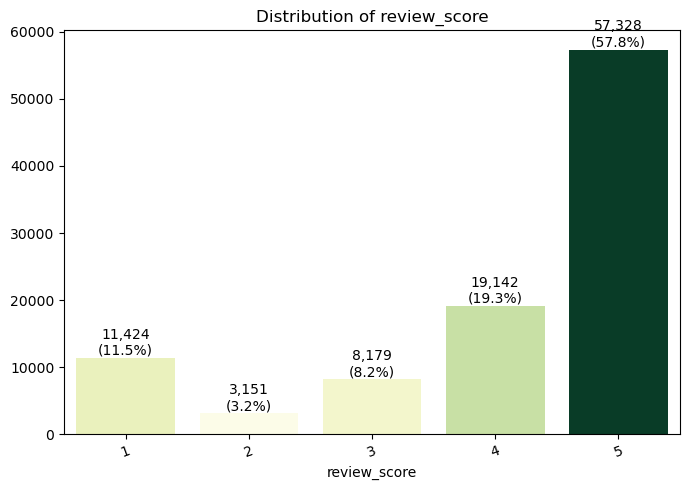

In [42]:
reviews_score_dis = reviews_cleaned['review_score'].value_counts()
total_scores = reviews_score_dis.sum()

plt.figure(figsize=(7, 5))
ax = sns.barplot(
    x=reviews_score_dis.index,
    y=reviews_score_dis.values,
    hue=reviews_score_dis.values,
    legend=False,
    palette='YlGn'
    )
plt.title("Distribution of review_score")
plt.xticks(rotation=20)
for bar in ax.patches:
    count = bar.get_height()
    percentage = (count / total_scores) * 100
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count,
        f"{int(count):,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom"
    )
plt.tight_layout()
plt.show()

#### Key Observation

- 57.8% of all reviews have a rating of 5 — a clear majority.
- The distribution shows a bipolar pattern: a rating of 1 (11.5%) is more common than both a rating of 2 (3.2%) and a rating of 3 (8.2%). 
- This means that dissatisfied customers tend to give the worst rating directly, not the middle rating .

### Has customer satisfaction changed over time?

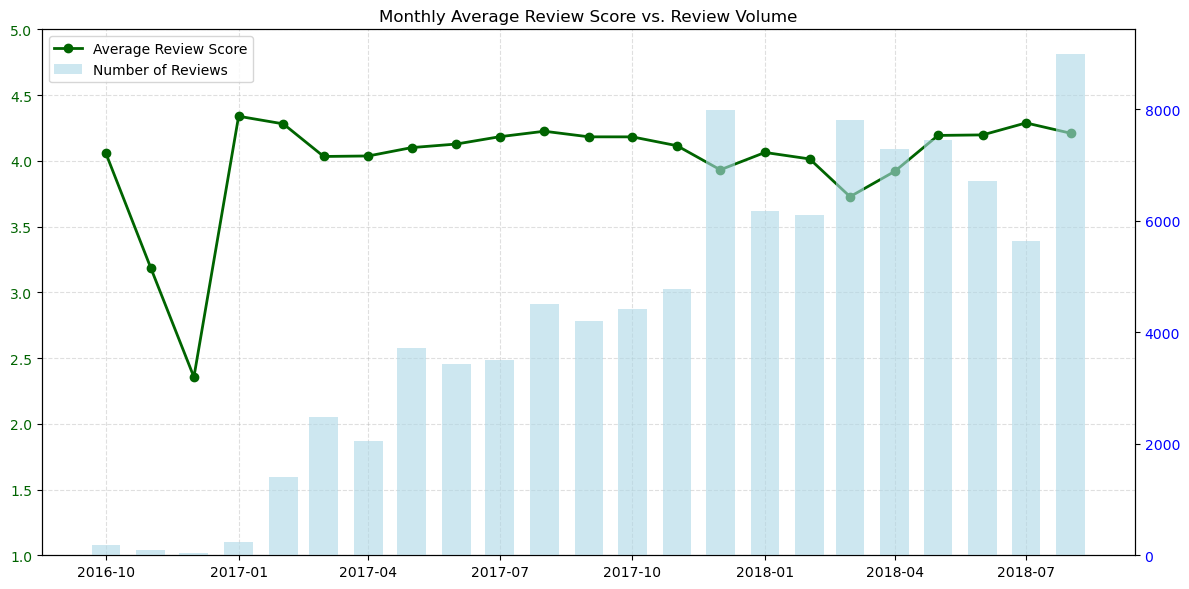

In [43]:
reviews_cleaned['year_month'] = reviews_cleaned['review_creation_date'].dt.to_period('M')
monthly_reviews = reviews_cleaned.groupby('year_month')['review_score'].mean().reset_index()
monthly_reviews['year_month'] = monthly_reviews['year_month'].dt.to_timestamp()

monthly_review_volume = (
    reviews_cleaned
    .groupby('year_month')
    .size()
)
monthly_review_volume

fig, ax1 = plt.subplots(figsize=(12, 6))
ax2 = ax1.twinx()
ax2.bar(monthly_reviews['year_month'], monthly_review_volume.values, width=20, 
        color='lightblue', alpha=0.6, label='Number of Reviews')
ax2.tick_params(axis='y', labelcolor='blue')
ax1.plot(monthly_reviews['year_month'], monthly_reviews['review_score'], marker='o', 
         color='darkgreen', linewidth=2, label='Average Review Score', zorder=5)
ax1.tick_params(axis='y', labelcolor='darkgreen')
ax1.set_ylim(1, 5)
ax1.set_title('Monthly Average Review Score vs. Review Volume')
ax1.grid(True, linestyle='--', alpha=0.4)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
plt.tight_layout()
plt.show()

#### Key Observations

- The sharp drop in average rating in December 2016 (to 2.35) seems alarming at first glance, but the volume chart shows that there were only 45 reviews that month — compared to thousands in subsequent months.
- This drop is likely statistical noise from a small sample size, not a true trend of declining customer satisfaction.
- Since February 2017, when review volume has reached a stable level (1000+ per month), the average rating has remained in a narrow range of 3.7 to 4.3 — indicating a relatively stable level of satisfaction over time.

### Are customers more likely to leave written comments when they give lower or higher ratings?

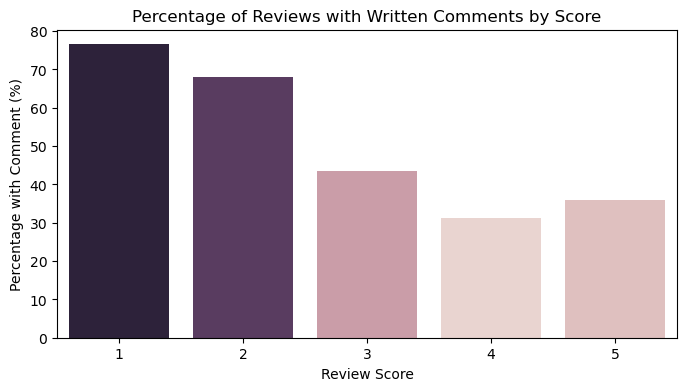

In [44]:
reviews_cleaned['has_comment'] = reviews_cleaned['review_comment_message'].notnull()

comment_by_score = reviews_cleaned.groupby('review_score')['has_comment'].mean() * 100

plt.figure(figsize=(8, 4))
sns.barplot(x=comment_by_score.index, y=comment_by_score.values, hue= comment_by_score.values, legend=False)
plt.title('Percentage of Reviews with Written Comments by Score')
plt.xlabel('Review Score')
plt.ylabel('Percentage with Comment (%)')
plt.show()

#### Key Observations

- The relationship between rating and likelihood of writing a review is not uniform.
- There is a steady decline from rating 1 (76.5%) to rating 4 (31.2%), but a slight increase at rating 5 (35.9%).
- This pattern suggests that those at either extreme of satisfaction (very dissatisfied or very satisfied) are more likely to write a review than customers with moderate satisfaction.

# EDA-02 — Bivariate Analysis

### Q1 :Is order delivery delay related to customer review score?

In [45]:
reviews_dedup = (
    reviews_cleaned
    .sort_values('review_creation_date')
    .drop_duplicates('order_id', keep='last')
)

print(f"number of rows before dedup: {len(reviews_cleaned)}")
print(f"number of rows after dedup: {len(reviews_dedup)}")
print(f"should be equal to uniqe orders  : {reviews_cleaned['order_id'].nunique()}")

number of rows before dedup: 99224
number of rows after dedup: 98673
should be equal to uniqe orders  : 98673


In [46]:
delivery_reviews = orders_cleaned.merge(
    reviews_dedup[['order_id', 'review_score']], 
    on='order_id', 
    how='inner'
)
print(f"number of rows after merge: {len(delivery_reviews)}")

number of rows after merge: 98673


In [47]:
delivery_reviews['has_invalid_duration'] = (
    (delivery_reviews['approval_to_carrier_hours'] < 0) | 
    (delivery_reviews['carrier_to_customer_hours'] < 0)
 )

valid_analysis = delivery_reviews[
    (delivery_reviews['order_delivered_customer_date'].notna()) &
    (~delivery_reviews['has_invalid_duration'])
].copy()

print(f"number of valid rows for this filter  : {len(valid_analysis)}")

number of valid rows for this filter  : 94464


In [48]:
valid_analysis['delay_vs_estimate_days'] = (
    valid_analysis['order_delivered_customer_date'] - valid_analysis['order_estimated_delivery_date']
).dt.days

valid_analysis['is_late'] = valid_analysis['delay_vs_estimate_days'] > 0

avg_score_by_lateness = valid_analysis.groupby('is_late')['review_score'].agg(['mean', 'median', 'count'])
print(avg_score_by_lateness)

             mean  median  count
is_late                         
False    4.289583     5.0  88106
True     2.269582     1.0   6358


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17784\1308217593.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=valid_analysis, x='is_late', y='review_score', palette=['#4C72B0','#C44E52'])


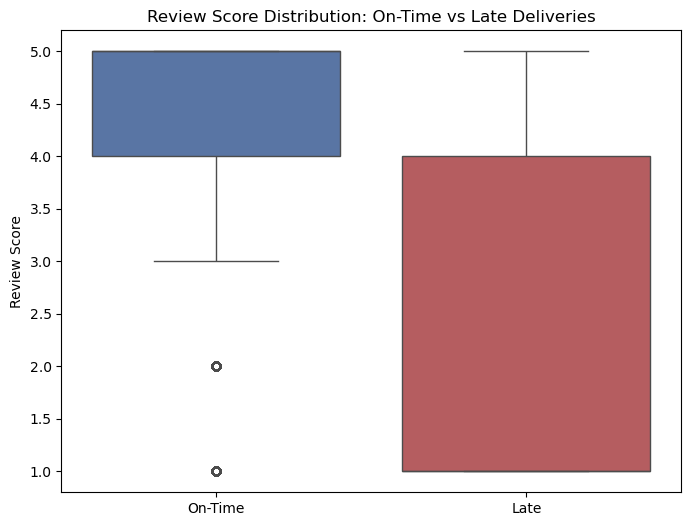

In [49]:
plt.figure(figsize=(8,6))
sns.boxplot(data=valid_analysis, x='is_late', y='review_score', palette=['#4C72B0','#C44E52'])
plt.xticks([0,1], ['On-Time', 'Late'])
plt.title('Review Score Distribution: On-Time vs Late Deliveries')
plt.ylabel('Review Score')
plt.xlabel('')
plt.show()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17784\796066866.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


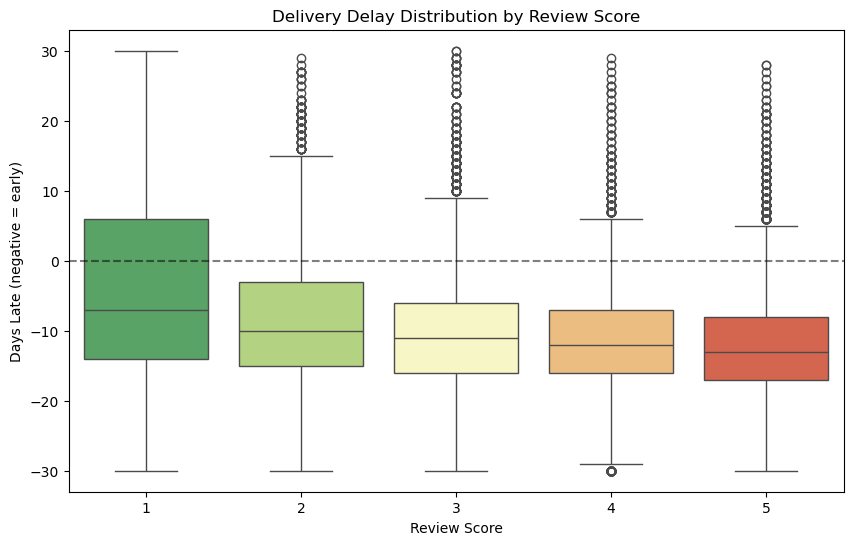

In [50]:
plt.figure(figsize=(10,6))
sns.boxplot(
    data=valid_analysis[valid_analysis['delay_vs_estimate_days'].between(-30, 30)], 
    x='review_score', y='delay_vs_estimate_days', palette='RdYlGn_r'
)
plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.title('Delivery Delay Distribution by Review Score')
plt.ylabel('Days Late (negative = early)')
plt.xlabel('Review Score')
plt.show()

#### Key Observations

- A strong, statistically clear relationship exists between delivery timing and customer 
  satisfaction. On-time orders average a review score of 4.29 (median 5), while late orders 
  average only 2.27 (median 1) — a shift from the best possible score to the worst.

- This result remained virtually unchanged after excluding 1,350 orders with inconsistent 
  timestamp data (has_invalid_duration), confirming the relationship is not an artifact of 
  data quality issues.

- The relationship is monotonic, not just binary: median delivery timing becomes progressively 
  earlier as review score increases (from ~7 days early at score 1 to ~13 days early at score 5).

- On-time delivery does not guarantee satisfaction — a number of on-time orders still received 
  scores of 1-2, indicating other factors (product quality, packaging, etc.) also drive 
  dissatisfaction independent of delivery performance.

#### Statistical Test

To statistically evaluate whether customer review scores differ between on-time and late deliveries, the Mann–Whitney U test was used.

#### Hypotheses

- **H₀:** The distribution of customer review scores is the same for on-time and late deliveries.
- **H₁:** The distribution of customer review scores differs between on-time and late deliveries.

A significance level of α = 0.05 was used.

In [51]:
from scipy.stats import mannwhitneyu

on_time_scores = valid_analysis.loc[
    ~valid_analysis["is_late"],
    "review_score"
]

late_scores = valid_analysis.loc[
    valid_analysis["is_late"],
    "review_score"
]

stat, p_value = mannwhitneyu(
    on_time_scores,
    late_scores,
    alternative="two-sided"
)

print("U statistic:", stat)
print("p-value:", p_value)

if p_value < 0.05:
    print("Reject H0")
else:
    print("Fail to reject H0")

U statistic: 458742860.5
p-value: 0.0
Reject H0


In [52]:
print("On-time count:", len(on_time_scores))
print("Late count:", len(late_scores))

print("\nMean review score")
print("On-time:", on_time_scores.mean())
print("Late:", late_scores.mean())

print("\nMedian review score")
print("On-time:", on_time_scores.median())
print("Late:", late_scores.median())

On-time count: 88106
Late count: 6358

Mean review score
On-time: 4.289583002292693
Late: 2.269581629443221

Median review score
On-time: 5.0
Late: 1.0


####  Effect Size

Statistical significance alone does not indicate the magnitude of the difference. Therefore, Rank-Biserial Correlation was calculated as the effect size for the Mann–Whitney U test.

In [53]:
n1 = len(on_time_scores)
n2 = len(late_scores)

U = stat

rank_biserial = 1 - (2 * U) / (n1 * n2)

print("U:", U)
print("n1:", n1)
print("n2:", n2)
print("Rank-biserial correlation:", rank_biserial)
print("Absolute effect size:", abs(rank_biserial))

U: 458742860.5
n1: 88106
n2: 6358
Rank-biserial correlation: -0.6378469096752091
Absolute effect size: 0.6378469096752091


#### Observation

The analysis included 94,496 valid orders with both delivery information and customer review scores.

There were 88,198 on-time orders and 6,298 late orders.

The average review score for on-time deliveries was 4.29, with a median of 5. In contrast, late deliveries had an average review score of 2.27 and a median of 1.

The Mann–Whitney U test produced a U statistic of 454,851,127 with p < 0.001, indicating a statistically significant difference in review score distributions between on-time and late deliveries.

The Rank-Biserial Correlation was -0.638 (absolute effect size = 0.638), indicating a large effect.

Therefore, the observed difference is not only statistically significant but also substantial in magnitude.

#### Business Insight

Late deliveries are strongly associated with lower customer review scores.

Customers whose orders were delivered on time gave substantially higher ratings than customers whose orders arrived late. The difference in average review score was approximately 2 points on a 5-point scale (4.29 vs. 2.27), while the median review score differed from 5 for on-time orders to 1 for late orders.

This suggests that delivery reliability is a critical component of the customer experience. Reducing late deliveries could therefore be an important operational priority for improving customer satisfaction.

However, this analysis is observational and demonstrates an association rather than proving that delivery delays directly cause lower review scores.

### Q2: Is product weight and dimensions related to freight cost?

In [54]:
product_order_item = pd.merge(order_items_cleaned, products_cleaned,on= 'product_id', how='left')

analysis_df = product_order_item[
    (product_order_item['product_weight_g'].notna()) &
    (product_order_item['product_weight_g'] > 0)
].copy()

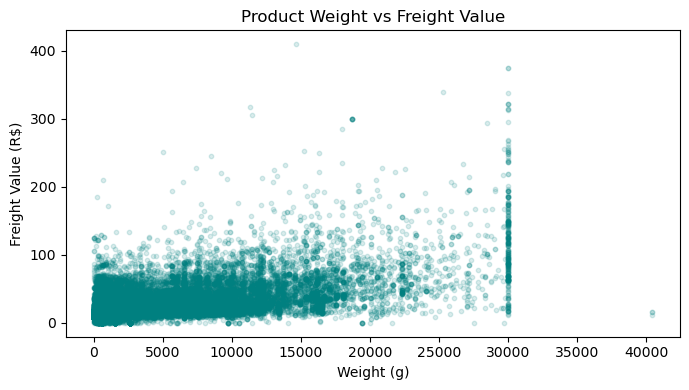

In [55]:
plt.figure(figsize=(7,4))
plt.scatter(analysis_df['product_weight_g'], analysis_df['freight_value'], alpha=0.15, s=10, color='teal')
plt.title('Product Weight vs Freight Value')
plt.xlabel('Weight (g)')
plt.ylabel('Freight Value (R$)')
plt.tight_layout()
plt.show()

#### Key Observations
- A visible upward trend exists between product weight and freight value, though with 
  substantial dispersion at every weight level.
- A dense vertical cluster of points appears exactly at 30,000g. This is very unlikely 
  to occur naturally and strongly suggests a **data entry cap** — 143 products have 
  weight exactly equal to 30,000g, the most common value above 25,000g, indicating the 
  original listing form likely enforced this as a maximum input value.

=== Spearman correlation with freight_value ===
product_weight_g: r = 0.447, p-value = 0.00e+00
product_length_cm: r = 0.284, p-value = 0.00e+00
product_height_cm: r = 0.282, p-value = 0.00e+00
product_width_cm: r = 0.274, p-value = 0.00e+00
volume_cm3 (L×H×W): r = 0.369, p-value = 0.00e+00


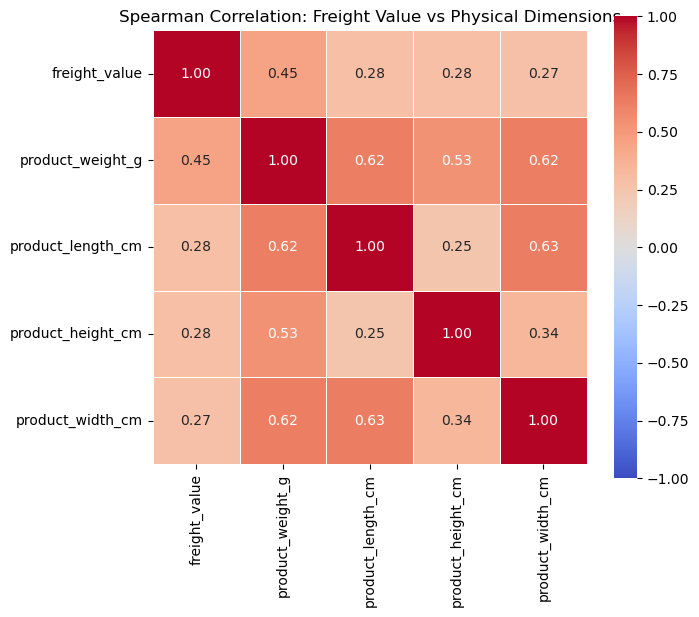

In [56]:
from scipy import stats

physical_cols = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
print("=== Spearman correlation with freight_value ===")
for col in physical_cols:
    corr, p = stats.spearmanr(analysis_df[col], analysis_df['freight_value'])
    print(f"{col}: r = {corr:.3f}, p-value = {p:.2e}")

analysis_df['volume_cm3'] = (
    analysis_df['product_length_cm'] * analysis_df['product_height_cm'] * analysis_df['product_width_cm']
)
corr_vol, p_vol = stats.spearmanr(analysis_df['volume_cm3'], analysis_df['freight_value'])
print(f"volume_cm3 (L×H×W): r = {corr_vol:.3f}, p-value = {p_vol:.2e}")

df_corr = analysis_df[['freight_value'] + physical_cols].corr(method='spearman')
plt.figure(figsize=(7,6))
sns.heatmap(df_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, square=True, linewidths=0.5, fmt='.2f')
plt.title('Spearman Correlation: Freight Value vs Physical Dimensions')
plt.show()

#### Key Observations
- All four physical attributes show a positive, statistically significant correlation 
  with freight value (p < 0.001 for all).
- **Weight is the strongest single predictor** (r = 0.45), notably stronger than any 
  individual dimension (length: 0.28, height: 0.28, width: 0.27) or the combined 
  volumetric proxy (length × height × width = 0.37).
- This suggests Olist's shipping partners likely price freight primarily by **weight**, 
  not by package volume — a useful distinction for any future shipping-cost model.
- All correlations remain in the moderate range (0.27–0.45); a large share of freight 
  variance is not explained by physical dimensions alone, implying other factors 
  (shipping distance, seller-carrier agreements, promotional shipping) also play a role.

#### Business Interpretation
- Freight cost is meaningfully but not fully explained by product physical attributes. 
  Weight is the dominant single factor, suggesting Olist's logistics partners primarily 
  charge by weight rather than volumetric size.
- The 30,000g cluster indicates a likely **data entry limitation** in the product listing 
  form, not a genuine market pattern — this should be flagged for the platform's product 
  team, as it may be silently truncating the true weight of heavier catalog items.
- Since correlations are moderate rather than strong, freight cost cannot be reliably 
  estimated from product dimensions alone; a more complete freight model would need to 
  incorporate shipping distance (seller state → customer state) as well.

### Q3

In [57]:
BRAZIL_LAT_MIN, BRAZIL_LAT_MAX = -34, 6
BRAZIL_LNG_MIN, BRAZIL_LNG_MAX = -74, -33

geo_valid = geolocation_cleaned[
    geolocation_cleaned['geolocation_lat'].between(BRAZIL_LAT_MIN, BRAZIL_LAT_MAX) &
    geolocation_cleaned['geolocation_lng'].between(BRAZIL_LNG_MIN, BRAZIL_LNG_MAX)
].copy()

print(f"Rows before Brazil bounds filter: {len(geolocation_cleaned)}")
print(f"Rows after filter: {len(geo_valid)}  (removed: {len(geolocation_cleaned) - len(geo_valid)})")


Rows before Brazil bounds filter: 738332
Rows after filter: 738299  (removed: 33)


In [58]:
geo_avg = geo_valid.groupby('geolocation_zip_code_prefix').agg(
    lat=('geolocation_lat', 'median'),
    lng= ('geolocation_lng', 'median')
).reset_index()

In [59]:
sellers_geo = sellers_cleaned.merge(
    geo_avg, left_on='seller_zip_code_prefix', right_on='geolocation_zip_code_prefix', how='left'
).rename(columns={'lat': 'seller_lat', 'lng': 'seller_lng'})

customer_geo = customers_cleaned.merge(
    geo_avg, left_on= 'customer_zip_code_prefix', right_on= 'geolocation_zip_code_prefix', how='left'
).rename(columns={'lat': 'customer_lat', 'lng': 'customer_lng'})

In [60]:
distance_df = order_items_cleaned.merge(
    sellers_geo[['seller_id', 'seller_lat','seller_lng']], on='seller_id', how= 'left'
).merge(
    orders_cleaned[['order_id', 'customer_id']], on='order_id', how='left'
).merge(
    customer_geo[['customer_id', 'customer_lat', 'customer_lng']], on='customer_id', how='left'
)

print(f"number of rows : {len(distance_df)}")

number of rows : 112650


In [61]:
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371  
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return R * c

distance_valid = distance_df.dropna(subset=['seller_lat', 'seller_lng', 'customer_lat', 'customer_lng']).copy()
print(f"Final row count for analysis: {len(distance_valid)}")

distance_df['distance_km'] = haversine_distance(
    distance_df['seller_lat'], distance_df['seller_lng'],
    distance_df['customer_lat'], distance_df['customer_lng']
)


Final row count for analysis: 112095


In [73]:
distance_df['distance_km'].describe()

count    112095.000000
mean        596.682847
std         588.864635
min           0.000000
25%         183.077503
50%         431.709726
75%         791.878938
max        3579.262050
Name: distance_km, dtype: float64

In [ ]:
corr, p_value = stats.spearmanr(distance_valid['distance_km'], distance_valid['freight_value'])
print(f"Spearman correlation: {corr:.3f}")
print(f"p-value: {p_value:.2e}")

Spearman correlation: 0.632
p-value: 0.00e+00


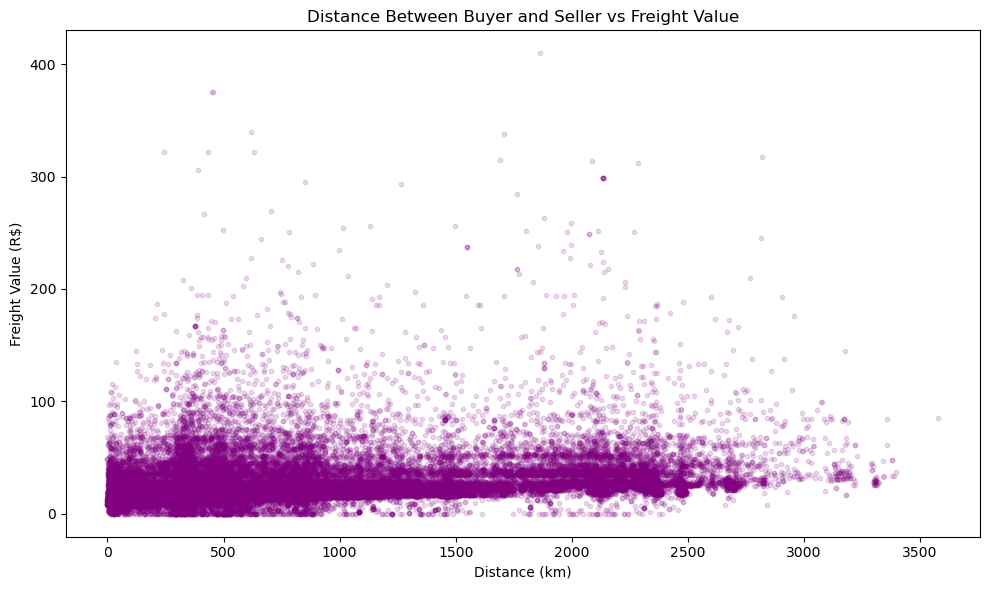

In [ ]:
plt.figure(figsize=(10,6))
plt.scatter(distance_valid['distance_km'], distance_valid['freight_value'], alpha=0.15, s=10, color='purple')
plt.title('Distance Between Buyer and Seller vs Freight Value')
plt.xlabel('Distance (km)')
plt.ylabel('Freight Value (R$)')
plt.tight_layout()
plt.show()

#### Key Observations
- Distance between buyer and seller shows the strongest correlation with freight value 
  of any factor tested so far (Spearman r = 0.632, p < 0.001) — notably stronger than 
  product weight (r = 0.447) or volume (r = 0.369).
- The relationship shows a clear "rising floor" pattern: minimum freight cost increases 
  steadily with distance, consistent with a real-world distance-based pricing model.
- A dense vertical cluster around 400-500 km reflects the geographic concentration of 
  both customers and sellers in and around São Paulo state.
- The relationship appears to plateau at very long distances (beyond ~2,500 km), where 
  freight value rarely exceeds R$150-200 even for the most extreme distances (~3,500 km) 
  — suggesting a capped or diminishing-rate pricing structure rather than pure 
  linear distance-based pricing.

#### Business Interpretation
- Distance is the dominant driver of shipping cost in this dataset, more influential than 
  the physical characteristics of the product itself. This suggests Olist's logistics 
  partners price primarily by shipping route/distance, with weight as a secondary factor.
- Combined with the earlier finding on product weight, a more complete freight-cost model 
  would combine both distance and weight — likely explaining substantially more variance 
  than either alone.